# NetHunt — Network Threat Hunt

**Hunt hypothesis:** an insider or external actor is using the network in a way
that each single connection looks legitimate, but whose *behavior over time*
deviates from how the host normally acts — low-and-slow C2 beaconing, DNS
tunneling, bulk data exfiltration, scanning, or lateral movement.

**Method:** baseline each host from Zeek `conn.log` + `dns.log`, score deviations
with robust statistics, corroborate against a threat-intel feed, and map every
finding to **MITRE ATT&CK** and the **Diamond Model**.

This notebook is the investigative, narrative companion to the batch pipeline in
`python -m nethunt.cli`.

## 0. Setup

In [1]:
import sys; sys.path.insert(0, '../src')
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
pd.set_option('display.width', 120); pd.set_option('display.max_columns', 20)

from nethunt.ingest import load_all
from nethunt.baseline import build_host_baseline, beacon_scores
from nethunt.intel import load_intel
from nethunt.detections import run_all
from nethunt.findings import dedup

Matplotlib is building the font cache; this may take a moment.


## 1. Load and normalize the telemetry

Both Zeek logs are normalized into one tidy schema so the hunt logic never has
to care which log a field came from.

In [2]:
data = load_all('../data')
conn, dns = data['conn'], data['dns']
print(f'conn flows: {len(conn):,}   dns queries: {len(dns):,}')
print(f'hosts: {conn.orig_h.nunique()}   window: {conn.datetime.min()} -> {conn.datetime.max()}')
conn[['datetime','orig_h','resp_h','resp_p','service','orig_bytes','resp_bytes','conn_state']].head()

conn flows: 6,039   dns queries: 2,394
hosts: 30   window: 2026-10-12 00:01:54.353064060+00:00 -> 2026-10-12 23:59:57.074969053+00:00


,datetime,orig_h,resp_h,resp_p,service,orig_bytes,resp_bytes,conn_state
0,2026-10-12 00:01:54.353064060+00:00,10.10.0.35,52.84.150.10,443,http,84,351,SF
1,2026-10-12 00:01:57.323251963+00:00,10.10.0.11,13.107.42.14,443,ssl,311,960,SF
2,2026-10-12 00:02:26.623883009+00:00,10.10.0.36,151.101.1.69,443,http,548,3956,SF
3,2026-10-12 00:03:15.098550081+00:00,10.10.0.24,13.107.42.14,443,http,1656,1229,SF
4,2026-10-12 00:04:04.305943966+00:00,10.10.0.39,13.107.42.14,443,ssl,237,1521,SF


## 2. Baseline normal behavior per host

We roll each host up into behavioral features and score deviations with a
**robust** (median/MAD) z-score, so a single massive attack value can't poison
the baseline meant to catch it.

In [3]:
baseline = build_host_baseline(conn, dns)
baseline.table[['conn_count','bytes_out_total','distinct_resp_ports',
                'failed_conn_ratio','internal_admin_fanout',
                'dns_txt_count','max_dns_entropy']].describe().round(2)

,conn_count,bytes_out_total,distinct_resp_ports,failed_conn_ratio,internal_admin_fanout,dns_txt_count,max_dns_entropy
count,30.00,3.000000e+01,30.00,30.00,30.00,30.00,30.00
mean,201.30,1.369888e+08,2.97,0.03,7.17,13.33,3.16
std,129.13,7.492469e+08,1.65,0.14,34.20,73.03,0.25
min,106.00,1.029280e+05,2.00,0.00,0.00,0.00,2.75
25%,151.75,1.578875e+05,2.00,0.00,0.00,0.00,3.12
50%,179.00,1.814040e+05,3.00,0.00,1.00,0.00,3.12
75%,195.75,2.231512e+05,3.00,0.00,1.00,0.00,3.12
max,762.00,4.103990e+09,11.00,0.79,188.00,400.00,4.43


### 2a. Where do the outliers live?
Rank hosts by outbound-volume z-score. One host should stand far off the fleet.

In [4]:
z_bytes = baseline.zscores('bytes_out_total').sort_values(ascending=False)
z_bytes.head(5).round(1)

orig_h
10.10.0.18    79979.8
10.10.0.14        5.6
10.10.0.22        3.2
10.10.0.11        1.6
10.10.0.39        1.0
Name: bytes_out_total, dtype: float64

## 3. Hunt 1 — C2 beaconing (behavioral)

C2 implants phone home on a timer. We measure the **coefficient of variation**
(CV = std/mean) of inter-arrival gaps per (src, dst) pair. Low CV = metronome =
automation. Human browsing is bursty (high CV).

In [5]:
beacons = beacon_scores(conn)
beacons.head(5)

,orig_h,resp_h,events,mean_interval_s,cv,regularity
0,10.10.0.22,185.220.101.45,361,59.99,0.0146,0.9856
1,10.10.0.14,151.101.1.69,21,3764.38,0.5637,0.6395
2,10.10.0.21,31.13.66.35,31,2793.95,0.7645,0.5667
3,10.10.0.25,151.101.1.69,27,2757.53,0.7803,0.5617
4,10.10.0.10,140.82.112.3,29,2824.51,0.7999,0.5556


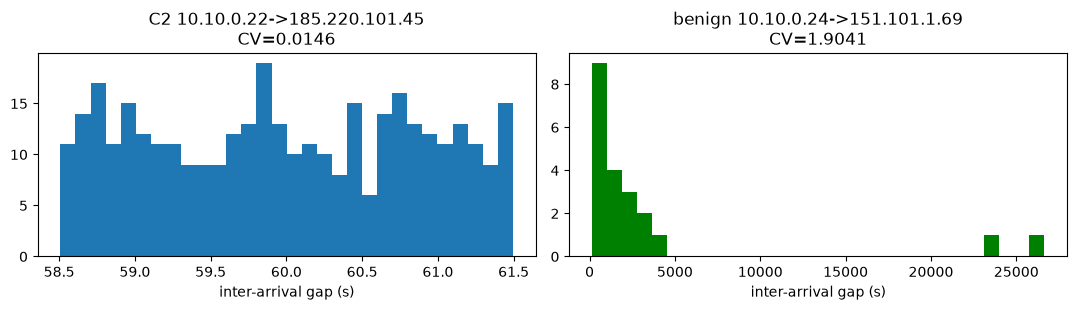

In [6]:
# visualize: the top beacon's gaps are tight; a benign pair's are scattered
top = beacons.iloc[0]
pair = conn[(conn.orig_h==top.orig_h) & (conn.resp_h==top.resp_h)].sort_values('ts')
gaps = np.diff(pair.ts.to_numpy())

benign = beacons.iloc[-1]
bpair = conn[(conn.orig_h==benign.orig_h)&(conn.resp_h==benign.resp_h)].sort_values('ts')
bgaps = np.diff(bpair.ts.to_numpy())

fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
ax[0].hist(gaps, bins=30); ax[0].set_title(f'C2 {top.orig_h}->{top.resp_h}\nCV={top.cv}')
ax[0].set_xlabel('inter-arrival gap (s)')
ax[1].hist(bgaps, bins=30, color='green')
ax[1].set_title(f'benign {benign.orig_h}->{benign.resp_h}\nCV={benign.cv}')
ax[1].set_xlabel('inter-arrival gap (s)'); plt.tight_layout(); plt.show()

The C2 gaps collapse onto a single ~60s spike; benign gaps are spread out.
That regularity is the detection signal, independent of payload or volume.

## 4. Hunt 2 — Exfiltration (volume + DNS tunneling)

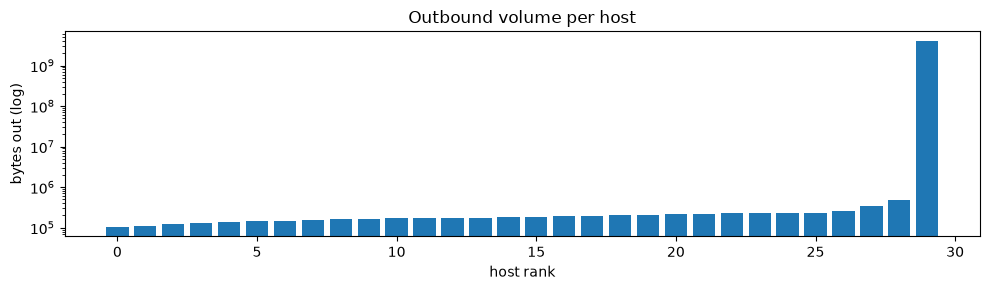

top talker: 10.10.0.18 4,104 MB


In [7]:
# 4a. outbound volume per host (log scale) — the exfil host dwarfs the fleet
bo = baseline.table['bytes_out_total'].sort_values()
plt.figure(figsize=(10,3))
plt.bar(range(len(bo)), bo.values)
plt.yscale('log'); plt.ylabel('bytes out (log)'); plt.xlabel('host rank')
plt.title('Outbound volume per host'); plt.tight_layout(); plt.show()
print('top talker:', bo.index[-1], f'{bo.iloc[-1]/1e6:,.0f} MB')

In [8]:
# 4b. DNS tunneling: long, high-entropy labels cluster on one parent domain
susp = dns[(dns.entropy>=3.5) & (dns.qname_len>=40)]
susp.groupby(['orig_h','parent_domain']).agg(queries=('query','size'), max_entropy=('entropy','max'), max_len=('qname_len','max')).sort_values('queries', ascending=False).head()

,,queries,max_entropy,max_len
orig_h,parent_domain,,,
10.10.0.31,exfil-cdn.net,400,4.434809,69


## 5. Intel-driven corroboration

Pivot from "what looks anomalous" to "what do we already know is bad". Matching
behavioral findings against the IOC feed raises confidence and attributes a
Diamond-Model adversary.

In [9]:
feed = load_intel('../data/intel_feed.json')
ext = conn[~conn.resp_h.str.startswith('10.10.0.')]
ext_bad = sorted(set(ext.resp_h) & feed.all_ips())
print('known-bad external IPs contacted:', ext_bad)
for ip in ext_bad:
    ind = feed.match_ip(ip)
    who = conn[conn.resp_h==ip].orig_h.unique()
    print(f'  {ip}  threat={ind["threat"]:18s} conf={ind["confidence"]:6s} hosts={list(who)}')

known-bad external IPs contacted: ['185.220.101.45', '193.201.9.7', '45.133.1.77']
  185.220.101.45  threat=COMMODITY-BEACON   conf=medium hosts=['10.10.0.22']
  193.201.9.7  threat=APT-DEMO-C2        conf=high   hosts=['10.10.0.19']
  45.133.1.77  threat=EXFIL-SINK         conf=low    hosts=['10.10.0.18']


## 6. Run the full detection suite

Everything above is the manual hunt. The same logic is codified in the detection
modules so it runs automatically and emits prioritized, analyst-ready findings.

In [10]:
findings = dedup(run_all(conn, dns, baseline, feed))
print(f'{len(findings)} findings\n')
for f in findings:
    print(f.summary_line())

10 findings

[CRITICAL] D003 score=100.0  10.10.0.18   T1030       Outbound data volume anomaly (possible exfiltration)  [INTEL]
[CRITICAL] D006 score=100.0  10.10.0.19   T1071       Connection to known-bad infrastructure (intel match)  [INTEL]
[HIGH    ] D001 score= 88.9  10.10.0.22   T1071.001   Periodic C2 beaconing to external host  [INTEL]
[HIGH    ] D006 score= 86.2  10.10.0.18   T1071       Connection to known-bad infrastructure (intel match)  [INTEL]
[HIGH    ] D006 score= 86.2  10.10.0.22   T1071       Connection to known-bad infrastructure (intel match)  [INTEL]
[HIGH    ] D002 score= 82.5  10.10.0.31   T1048.001   DNS tunneling / exfiltration over DNS  [INTEL]
[HIGH    ] D006 score= 82.5  10.10.0.31   T1071.004   DNS resolution of known-bad domain (intel match)  [INTEL]
[HIGH    ] D006 score= 82.5  10.10.0.19   T1071.004   DNS resolution of known-bad domain (intel match)  [INTEL]
[HIGH    ] D005 score= 61.5  10.10.0.14   T1021       Internal lateral movement over admin proto

### 6a. Top finding, fully contextualized (ATT&CK + Diamond + intel)

In [11]:
f = findings[0]
print(f'{f.detection_id}  {f.title}')
print('host     :', f.src_host)
print('severity :', f.severity, 'score', f.score)
print('ATT&CK   :', f.attack_technique, f.attack_technique_name, f'({f.attack_tactic})')
print('rationale:', f.rationale)
d = f.diamond
print('Diamond  : adversary=%s | capability=%s | infra=%s | victim=%s' %
      (d.adversary, d.capability, d.infrastructure, d.victim))
print('intel    :', f.intel[0]['threat'] if f.intel else 'none')

D003  Outbound data volume anomaly (possible exfiltration)
host     : 10.10.0.18
severity : critical score 100.0
ATT&CK   : T1030 Data Transfer Size Limits (Exfiltration)
rationale: Host sent 4,104 MB to 45.133.1.77, a robust z-score of 79,979.8 above fleet-normal outbound volume. Volume and single-destination concentration are consistent with bulk data exfiltration.
Diamond  : adversary=UNK | capability=Bulk data exfiltration over TLS | infra=45.133.1.77 | victim=10.10.0.18
intel    : EXFIL-SINK


## 7. ATT&CK coverage of this hunt

In [12]:
cov = pd.DataFrame([{
  'detection': f.detection_id, 'technique': f.attack_technique,
  'tactic': f.attack_tactic, 'host': f.src_host, 'score': f.score,
} for f in findings]).sort_values('score', ascending=False)
cov

,detection,technique,tactic,host,score
0,D003,T1030,Exfiltration,10.10.0.18,100.0
1,D006,T1071,Command and Control,10.10.0.19,100.0
2,D001,T1071.001,Command and Control,10.10.0.22,88.9
3,D006,T1071,Command and Control,10.10.0.18,86.2
4,D006,T1071,Command and Control,10.10.0.22,86.2
5,D002,T1048.001,Exfiltration,10.10.0.31,82.5
6,D006,T1071.004,Command and Control,10.10.0.31,82.5
7,D006,T1071.004,Command and Control,10.10.0.19,82.5
8,D005,T1021,Lateral Movement,10.10.0.14,61.5
9,D004,T1046,Discovery,10.10.0.27,40.0


## 8. Hunt conclusion

Starting from a behavioral hypothesis and zero prior IOCs, the hunt surfaced five
distinct TTPs and corroborated three of them against threat intel:

| Host | Behavior | ATT&CK | Intel |
|------|----------|--------|-------|
| .18 | 4 GB outbound to one sink | T1030 Exfiltration | EXFIL-SINK |
| .19 | contact with known C2 | T1071 C2 | APT-DEMO (high) |
| .22 | 60s beacon to external host | T1071.001 C2 | COMMODITY-BEACON |
| .31 | high-entropy DNS tunneling | T1048 Exfiltration | DNS-TUNNEL |
| .27 | port/host scan fan-out | T1046 Discovery | — |
| .14 | SMB/WinRM/RDP to 10 peers | T1021 Lateral Movement | — |

**Next actions:** isolate .18 and .19, pull host EDR on .22/.31, and feed the two
unknown external IPs back into the intel feed as new indicators to close the loop.

The `.27`/`.14` pair also shows the key false-positive discriminator: scanning is
failed, zero-byte probes; lateral movement is *established* admin sessions moving
data. Keying D005 on connection state keeps the scanner out of the lateral bucket.